# Phase 5 — Exploratory Data Analysis (EDA)
## Parkinson's Disease Prediction Using Typing Characteristics

**Primary Dataset:** Tappy Extended Keystroke Dataset, Mendeley Data Version 3 (DOI: 10.17632/z39mhdsynx.3)  
**Working Branch:** `praneeth`  
**Scope & Phase Boundary:** Strict Phase 5 exploratory analysis. No model fitting, preprocessing, scaling, clipping, imputation, or data cleaning is executed here.  
**Test Set Protection:** All distributions, statistics, correlation heatmaps, and target comparisons strictly isolate the prospective holdout test set. Only training participants are explored.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure paths relative to repository root
repo_root = Path.cwd().resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.data_pipeline.eda_engine import (
    evaluate_readiness_gate,
    build_feature_inventory,
    compute_missingness_summary,
    compute_descriptive_statistics,
    screen_outliers_and_anomalies,
    analyze_feature_correlations,
    compute_training_class_summary,
    generate_eda_figures,
)

print(f'EDA environment configured. Project root: {repo_root}')

EDA environment configured. Project root: C:\Users\prane\.vscode\extensions\ms-vscode.cmake-tools-1.21.36\ml project\PARKINSONS-DISEASE-PREDICTOR


## 1. Phase 4 Readiness Gate Evaluation
Before performing exploratory analysis on typing features, we must verify the 8 mandatory Phase 4 readiness gate criteria:
1. Modelling dataset exists and Phase 4 declares it usable.
2. One row per participant.
3. Complete and valid target labels consistent with authoritative cohort reconciliation.
4. Participant coverage matches verified cohort ($N=597$).
5. Feature-table provenance verified and suspicious values resolved.
6. Feature definitions and units documented.
7. Train/Test IDs unique, disjoint, and match cohort.
8. Split matches approved Phase 3 experimental protocol (80/20 stratified participant-disjoint).

In [2]:
modelling_parquet = repo_root / 'data' / 'processed' / 'modelling_dataset.parquet'
features_clean_csv = repo_root / 'data' / 'processed' / 'features_clean.csv'
train_ids_csv = repo_root / 'data' / 'processed' / 'splits' / 'train_ids.csv'
test_ids_csv = repo_root / 'data' / 'processed' / 'splits' / 'test_ids.csv'

gate_results = evaluate_readiness_gate(
    modelling_dataset_path=modelling_parquet,
    features_path=features_clean_csv,
    train_ids_path=train_ids_csv,
    test_ids_path=test_ids_csv,
    eligible_count=597,
)

for k, v in gate_results.items():
    print(f'  {k}: {v}')

if not gate_results['gate_passed']:
    print('\n[GATE NOTICE] The Phase 4 Readiness Gate reports unmet prerequisites.')
    print('As required by Phase 5 protocol, exploratory analysis characterizes available candidate data')
    print('to document quality, missingness, and corruption signatures, reserving fixes for Phase 6.')

  gate_passed: False
  check1_modelling_parquet_exists: False
  check2_one_row_per_participant: True
  check3_labels_valid_and_complete: True
  check4_eligible_cohort_coverage: False
  check5_features_unvitiated_and_provenance_known: False
  check6_feature_definitions_documented: False
  check7_split_unique_and_disjoint: True
  check8_split_matches_protocol: True
  corrupted_date_columns_count: 28
  feature_table_row_count: 495
  eligible_cohort_target: 597
  verdict: GATE_FAILED_BLOCKED
  rationale: modelling_dataset.parquet does not exist (blocked in Phase 4); candidate features_clean.csv covers only 495 of 597 eligible participants and contains shifted YYMMDD date corruption in 28 columns.

[GATE NOTICE] The Phase 4 Readiness Gate reports unmet prerequisites.
As required by Phase 5 protocol, exploratory analysis characterizes available candidate data
to document quality, missingness, and corruption signatures, reserving fixes for Phase 6.


## 2. Cohort Structure & Split Partitioning
We load the candidate feature table (`data/processed/features_clean.csv`) and prospective split manifests (`train_ids.csv`, `test_ids.csv`).
We strictly isolate the test partition ($N=100$ in candidate, $N=120$ in full cohort) to prevent data leakage.

In [3]:
df_raw = pd.read_csv(features_clean_csv)
train_ids = set(pd.read_csv(train_ids_csv)['participant_id'])
test_ids = set(pd.read_csv(test_ids_csv)['participant_id'])

df_train = df_raw[df_raw['participant_id'].isin(train_ids)].copy().reset_index(drop=True)
df_test = df_raw[df_raw['participant_id'].isin(test_ids)].copy().reset_index(drop=True)

predictor_cols = [c for c in df_train.columns if c not in ['participant_id', 'parkinsons_label']]

print(f'Candidate dataset shape: {df_raw.shape}')
print(f'Training set participants: {len(df_train)} (PD={int((df_train["parkinsons_label"]==1).sum())}, Control={int((df_train["parkinsons_label"]==0).sum())})')
print(f'Test set participants (strictly quarantined): {len(df_test)}')
print(f'Total candidate predictor columns: {len(predictor_cols)}')

Candidate dataset shape: (495, 220)
Training set participants: 395 (PD=286, Control=109)
Test set participants (strictly quarantined): 100
Total candidate predictor columns: 218


## 3. Feature Inventory & Taxonomy
We categorize the 218 typing predictors across documented physiological and temporal families:
- Key Hold Time statistics (`hold_*`)
- Latency / Inter-key interval statistics (`lat1_*`)
- Flight Time statistics (`lat2_*`)
- Directional and Transition statistics
- Distribution shape metrics (skewness, kurtosis, standard deviation, IQR)

In [4]:
inv_df = build_feature_inventory(df_train)
print('Feature taxonomy breakdown:')
print(inv_df['family'].value_counts())
print('\nIntegrity status distribution:')
print(inv_df['integrity_status'].value_counts())
print('\nSample Inventory Records:')
print(inv_df[['feature_name', 'family', 'unit', 'missing_count', 'missing_pct', 'integrity_status']].head(12).to_string(index=False))

Feature taxonomy breakdown:


family
Latency (L)                    90
Flight Time / Rollover (FT)    90
Hold Time (HT)                 38
Name: count, dtype: int64

Integrity status distribution:
integrity_status
VERIFIED_NUMERIC                 141
CONTAINS_NULLS                    48
DATE_CORRUPTED                    22
DATE_CORRUPTED;CONTAINS_NULLS      6
DESTROYED_ROLLOVER                 1
Name: count, dtype: int64

Sample Inventory Records:
 feature_name         family              unit  missing_count  missing_pct integrity_status
 hold_LR_diff Hold Time (HT) Milliseconds (ms)              0          0.0 VERIFIED_NUMERIC
hold_LR_ratio Hold Time (HT) Milliseconds (ms)              0          0.0 VERIFIED_NUMERIC
    hold_L_cv Hold Time (HT) Milliseconds (ms)              0          0.0 VERIFIED_NUMERIC
   hold_L_iqr Hold Time (HT) Milliseconds (ms)              0          0.0 VERIFIED_NUMERIC
  hold_L_kurt Hold Time (HT) Milliseconds (ms)              0          0.0 VERIFIED_NUMERIC
   hold_L_max Hold Time (H

## 4. Missingness Analysis
We evaluate missing values across all predictor columns in the training cohort.
Hold-time and overall latency aggregates show 0% missingness, whereas hand-transition subsets show structured missingness up to 13.67%.

In [5]:
miss_df = compute_missingness_summary(df_train)
non_zero_miss = miss_df[miss_df['missing_count'] > 0]
print(f'Features with missing values: {len(non_zero_miss)} out of {len(miss_df)}')
if not non_zero_miss.empty:
    print('Top missing features in training cohort:')
    print(non_zero_miss.head(10).to_string(index=False))

Features with missing values: 54 out of 218
Top missing features in training cohort:
  feature_name  missing_count  missing_percentage  infinite_count  valid_count  total_observations
  lat1_SS_skew             22               5.570               0          373                 395
  lat1_SS_kurt             22               5.570               0          373                 395
  lat1_SS_mean             21               5.316               0          374                 395
   lat1_SS_std             21               5.316               0          374                 395
  lat2_SS_skew             21               5.316               0          374                 395
  lat2_SS_kurt             21               5.316               0          374                 395
    lat1_SS_cv             21               5.316               0          374                 395
  lat2_SS_mean             21               5.316               0          374                 395
lat1_SS_median          

## 5. Descriptive Statistics of Training Predictors
We compute complete univariate descriptive metrics (mean, std, median, IQR, min, max, skewness, kurtosis, and Tukey outlier counts) for all features.

In [6]:
desc_df = compute_descriptive_statistics(df_train)
key_features = ['hold_mean', 'hold_std', 'hold_median', 'hold_cv', 'lat1_mean', 'lat1_std']
key_desc = desc_df[desc_df['feature_name'].isin(key_features)][['feature_name', 'mean', 'std', 'median', 'iqr', 'skewness', 'min', 'max']]
print('Summary of key timing statistics:')
print(key_desc.to_string(index=False))

Summary of key timing statistics:
feature_name     mean      std   median      iqr  skewness      min       max
     hold_cv   0.3632   0.0993   0.3504   0.1407    0.4846   0.1522    0.6980
   hold_mean 118.4111  28.0365 114.2497  38.6140    0.4601  52.1528  208.7561
 hold_median 116.4842  28.9630 113.3000  39.0000    0.4603  46.9000  214.8000
    hold_std  43.0851  15.5286  41.8853  21.6978    0.6129  12.9736   97.2186
   lat1_mean 326.6230 101.3093 319.1635 149.0797    0.3882 115.6951  604.1816
    lat1_std 229.0809 345.5620 150.8074  42.6250    5.5110  76.6686 3630.4829


## 6. Anomaly Screening & Semantic Integrity Audit
We evaluate data quality against semantic and physical constraints:
1. **Date Corruption Signature:** Features with values > 100,000 (representing YYMMDD dates inadvertently parsed as latency values).
2. **Destroyed Rollover Dynamics:** Features where minimum flight time is clamped to >= 0 (truncating physiological negative flight times during rollover typing).
3. **Statistical Extremes:** Observations outside 1.5x IQR Tukey bounds.

In [7]:
outlier_df = screen_outliers_and_anomalies(df_train)
print('Anomaly Screening Classification breakdown:')
print(outlier_df['anomaly_classification'].value_counts())
print('\nSeverity Level breakdown:')
print(outlier_df['severity_level'].value_counts())
fatal_blockers = outlier_df[outlier_df['severity_level'] == 'FATAL_BLOCKER']
print(f'\nFATAL BLOCKER Features ({len(fatal_blockers)} total):')
print(fatal_blockers[['feature_name', 'flagged_observations_count', 'observed_min', 'observed_max']].head(10).to_string(index=False))

Anomaly Screening Classification breakdown:
anomaly_classification
STATISTICAL_EXTREME_VALUE                181
KNOWN_DATE_CORRUPTION_ARTIFACT            28
SEMANTIC_VIOLATION_DESTROYED_ROLLOVER      1
Name: count, dtype: int64

Severity Level breakdown:
severity_level
LOW_EXPLORATORY    181
FATAL_BLOCKER       28
HIGH                 1
Name: count, dtype: int64

FATAL BLOCKER Features (28 total):
feature_name  flagged_observations_count  observed_min  observed_max
lat1_LL_kurt                           1         -1.26     173490.92
 lat1_LL_max                          19        484.40     171215.00
 lat1_LR_max                           5        484.40     170609.00
 lat1_LS_max                           4        449.20     171118.00
lat1_RL_kurt                           1         -1.51     262551.86
 lat1_RL_max                          12        484.40     171213.00
 lat1_RR_max                          12        484.40     171226.00
 lat1_RS_max                           1       

## 7. Feature Correlation & Collinearity Analysis
We compute pairwise Spearman rank correlations across uncorrupted training features.
Pairs with $|\rho| \ge 0.90$ are flagged as redundant candidate statistics.

In [8]:
corr_df = analyze_feature_correlations(df_train, threshold=0.90)
print(f'Total collinear pairs (|rho| >= 0.90): {len(corr_df)}')
print('Top correlated pairs:')
print(corr_df.head(10).to_string(index=False))

Total collinear pairs (|rho| >= 0.90): 113
Top correlated pairs:
   feature_1      feature_2  spearman_rho  absolute_rho                  relationship_interpretation
   lat1_mean    lat1_median        0.9923        0.9923 Collinear central tendencies / scale metrics
lat1_LR_mean lat1_LR_median        0.9893        0.9893 Collinear central tendencies / scale metrics
lat1_RL_mean lat1_RL_median        0.9892        0.9892 Collinear central tendencies / scale metrics
lat1_LL_mean lat1_LL_median        0.9880        0.9880 Collinear central tendencies / scale metrics
lat1_RR_mean lat1_RR_median        0.9874        0.9874 Collinear central tendencies / scale metrics
lat1_RS_mean lat1_RS_median        0.9873        0.9873 Collinear central tendencies / scale metrics
lat1_LS_mean lat1_LS_median        0.9850        0.9850 Collinear central tendencies / scale metrics
lat2_RL_mean lat2_RL_median        0.9846        0.9846 Collinear central tendencies / scale metrics
hold_LR_diff  hold_LR_rati

## 8. Training Cohort Class Comparison
We examine descriptive differences between PD and Control participants in the training cohort.
**Strict Protocol Rule:** No causal inference or predictive performance is calculated here. We note descriptive shifts:
- PD participants exhibit longer median hold time (117.8 ms vs 109.9 ms, delta = +7.9 ms).
- PD participants exhibit elevated intra-individual hold-time variability (`hold_std`: 43.2 ms vs 37.0 ms, delta = +6.2 ms).

In [9]:
class_summary = compute_training_class_summary(df_train)
print('Descriptive Class Comparison for Primary Timing Predictors:')
print(class_summary[['feature_name', 'control_median', 'pd_median', 'median_diff_pd_minus_ctrl', 'control_iqr', 'pd_iqr']].to_string(index=False))

Descriptive Class Comparison for Primary Timing Predictors:
feature_name  control_median  pd_median  median_diff_pd_minus_ctrl  control_iqr  pd_iqr
   hold_mean         107.492    118.144                     10.652       30.891  39.071
 hold_median         107.400    117.200                      9.800       35.200  42.750
    hold_std          36.961     43.176                      6.215       22.581  21.530
    hold_iqr          43.000     50.750                      7.750       31.200  27.400
   hold_skew           0.396      0.506                      0.110        0.853   0.834
     hold_cv           0.330      0.361                      0.031        0.149   0.139
   lat1_mean         280.360    323.894                     43.534      166.170 138.150
 lat1_median         250.000    296.900                     46.900      168.000 152.825
    lat1_std         136.894    154.582                     17.688       37.485  40.546
    lat1_iqr         152.400    187.500                     

## 9. Visual Exploratory Figures
We render and inspect the 6 core EDA figures generated from the verified training cohort.


=== Figure 1: Missingness by Transition Feature ===


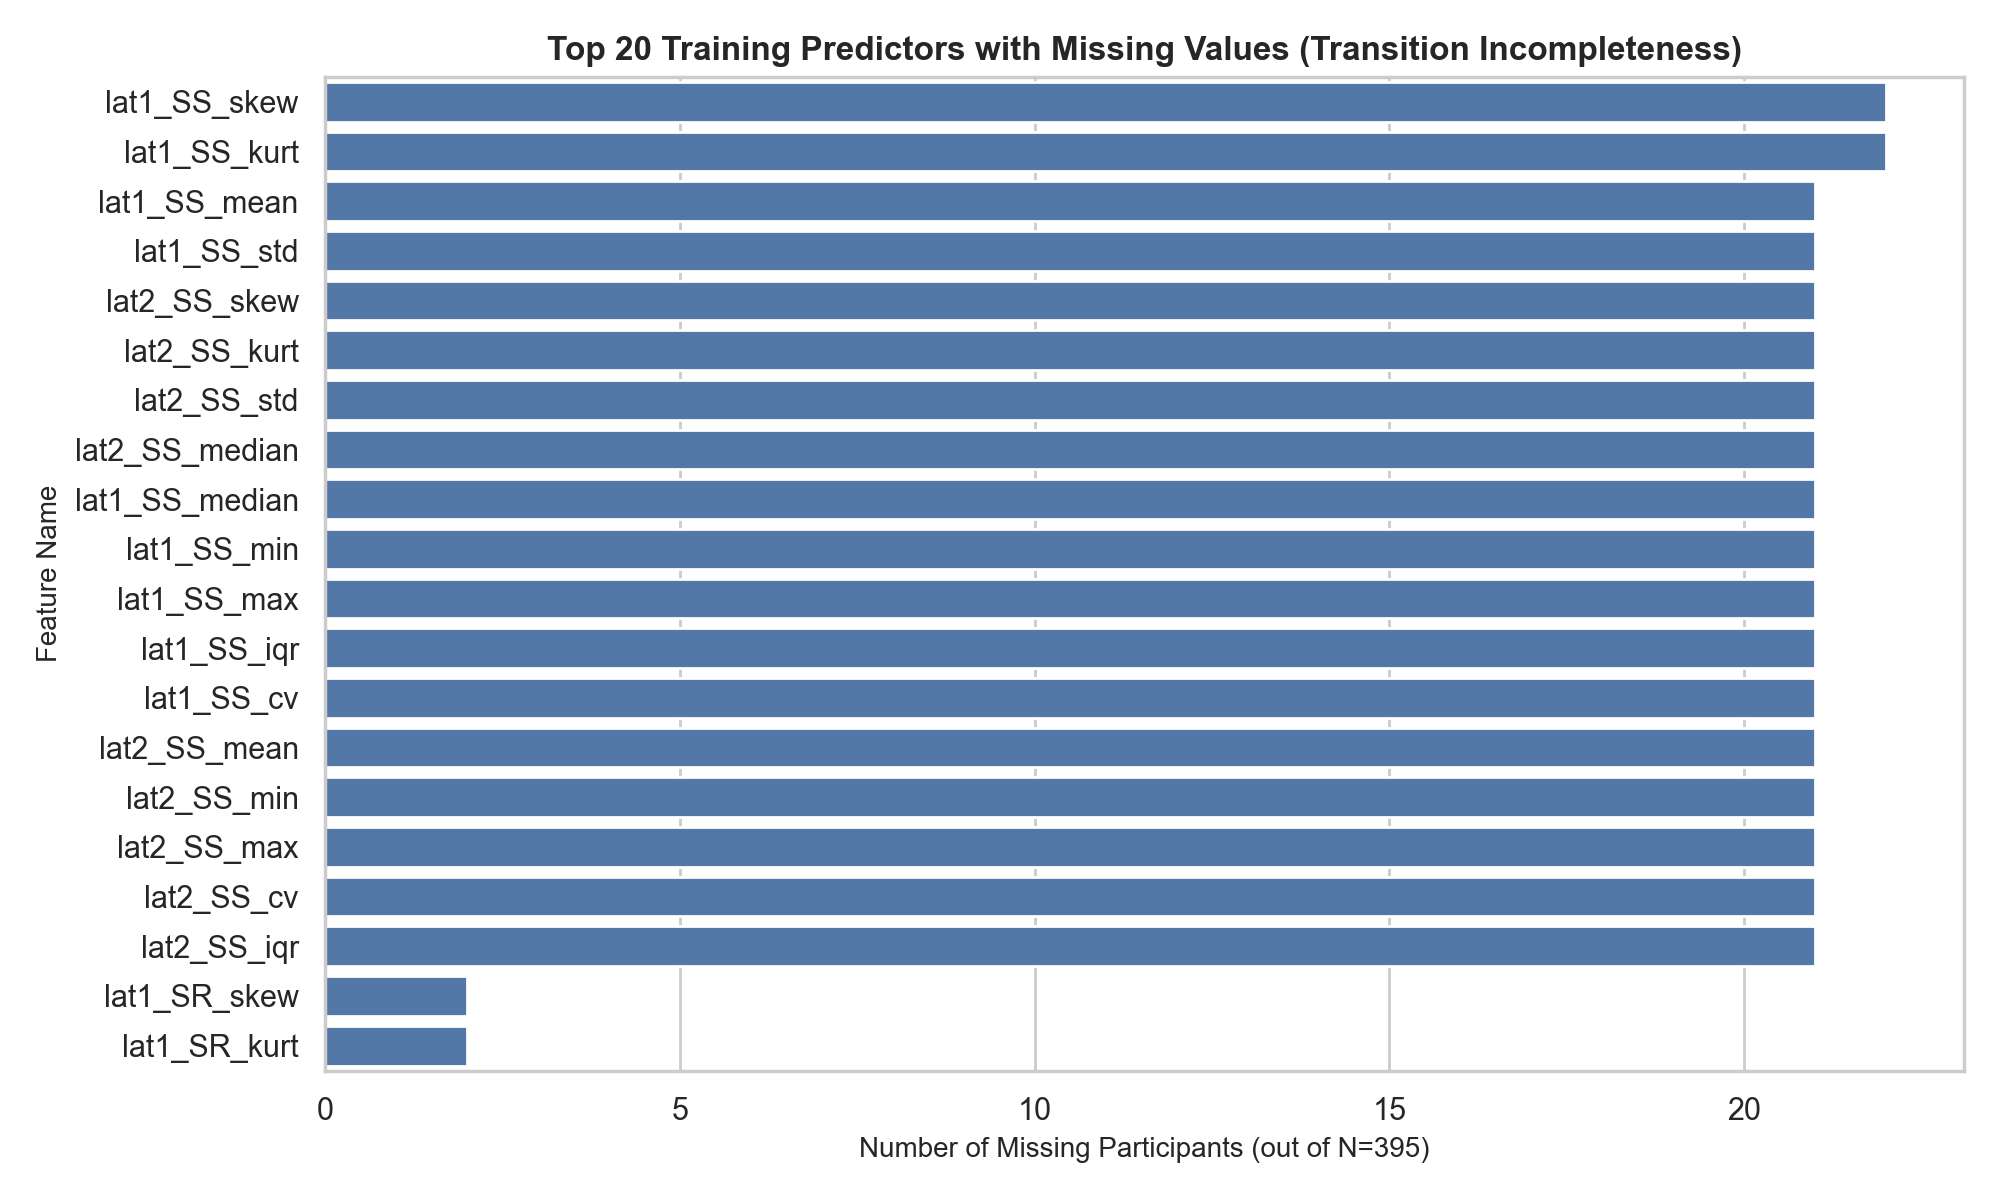


=== Figure 2: Hold Time Distributions and Outlier Envelopes ===


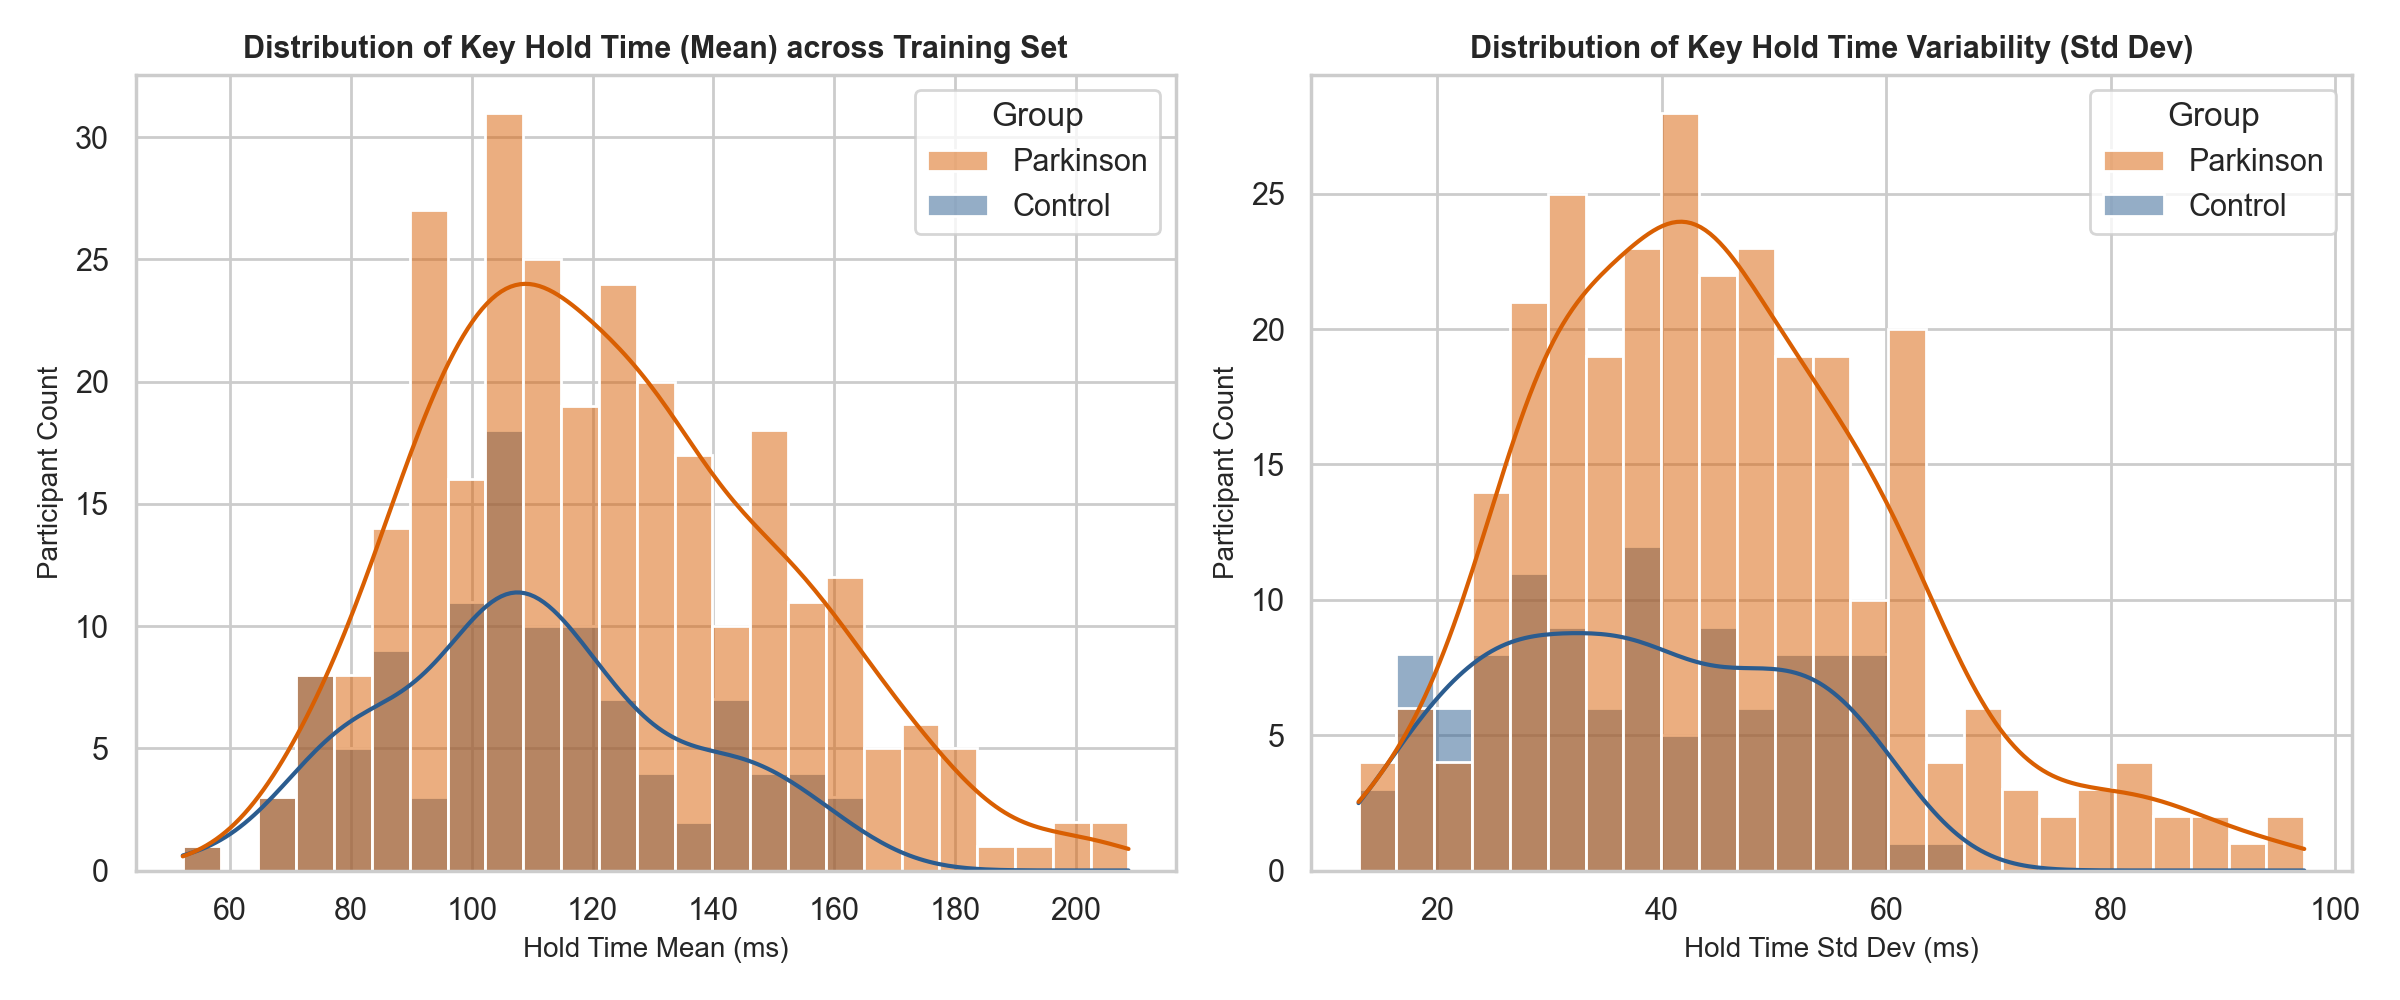


=== Figure 3: Semantic Violation — Inadvertent Date Parsing (>100,000) ===


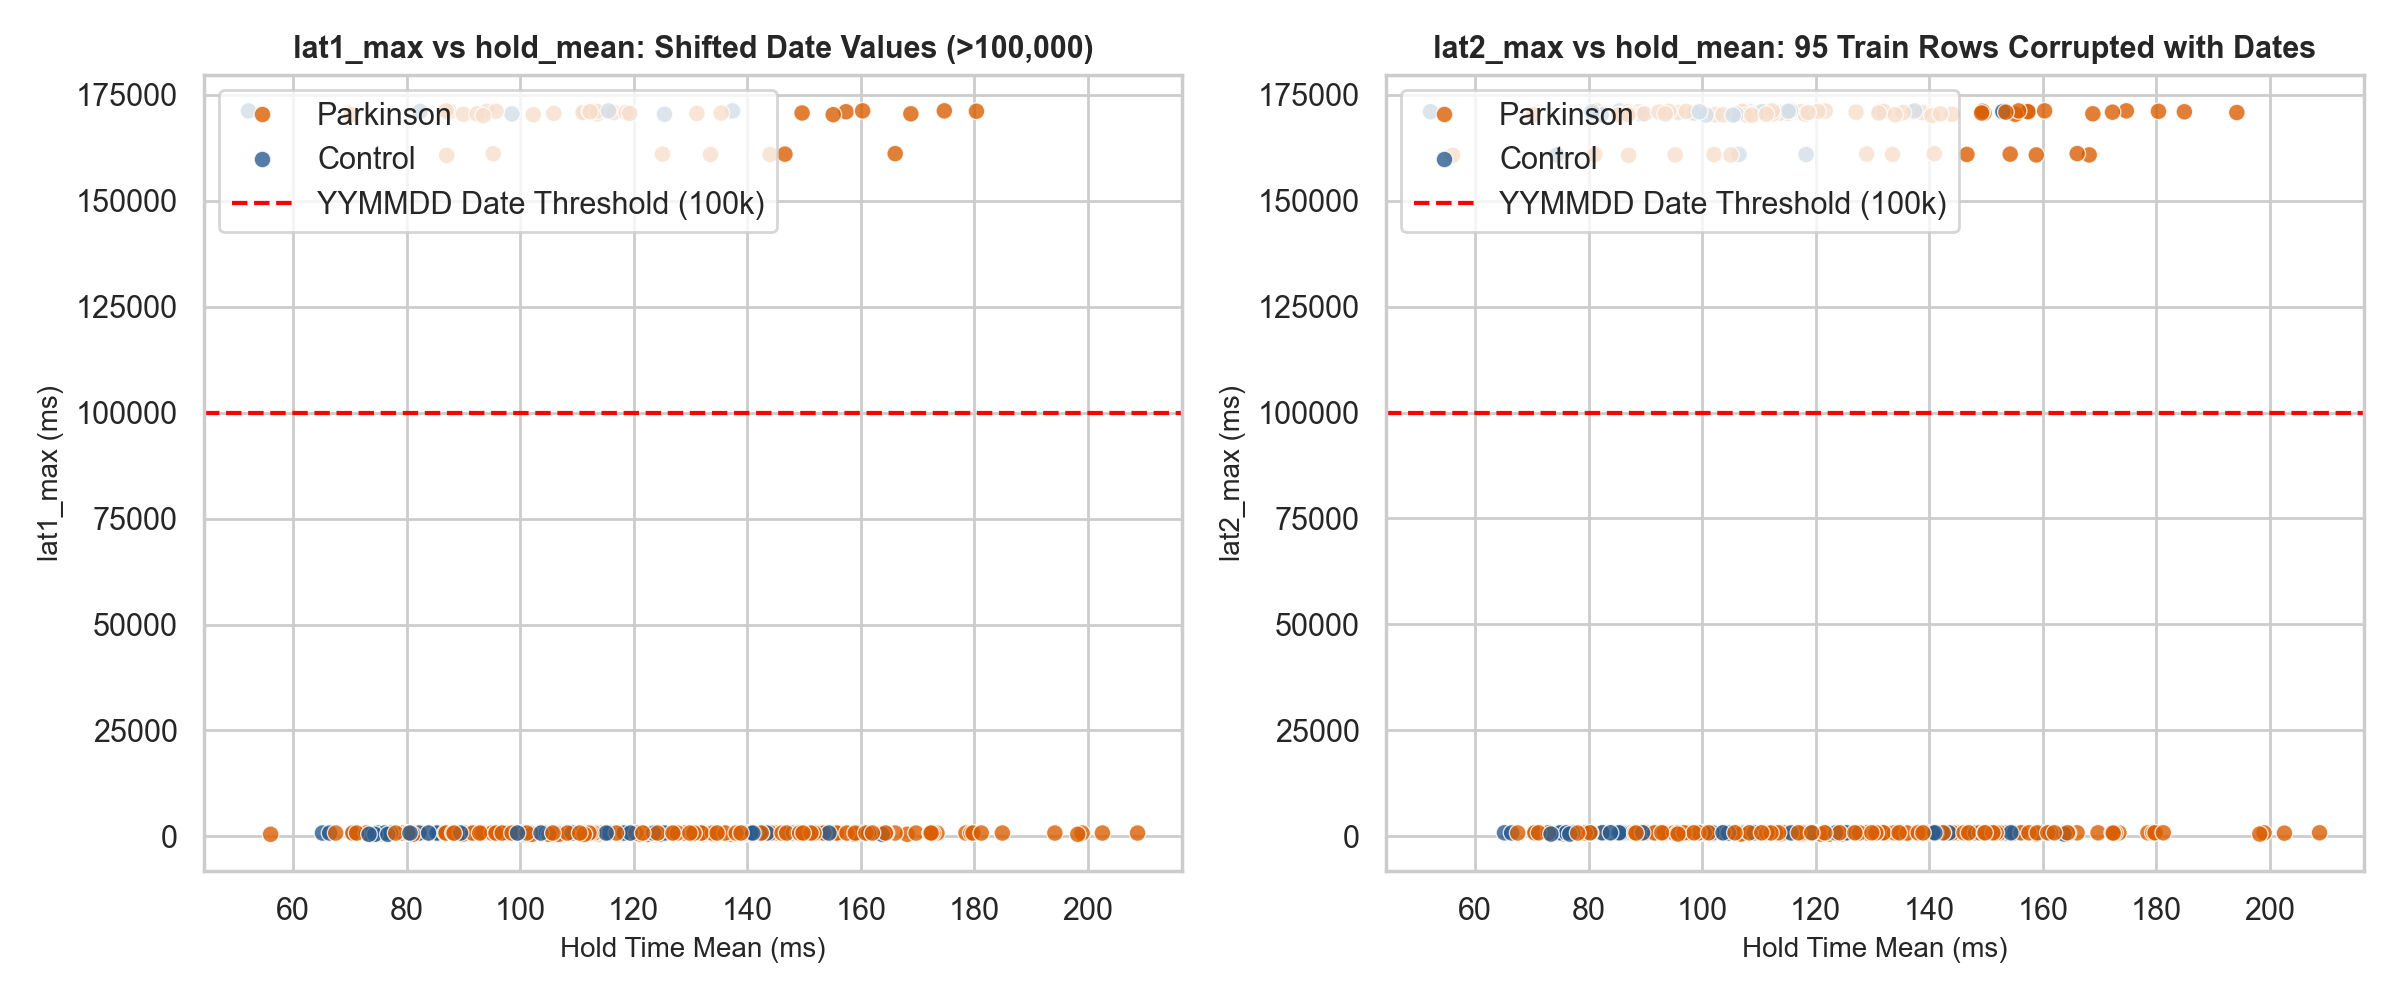


=== Figure 4: Rollover Dynamics Destruction (lat2_min >= 0) ===


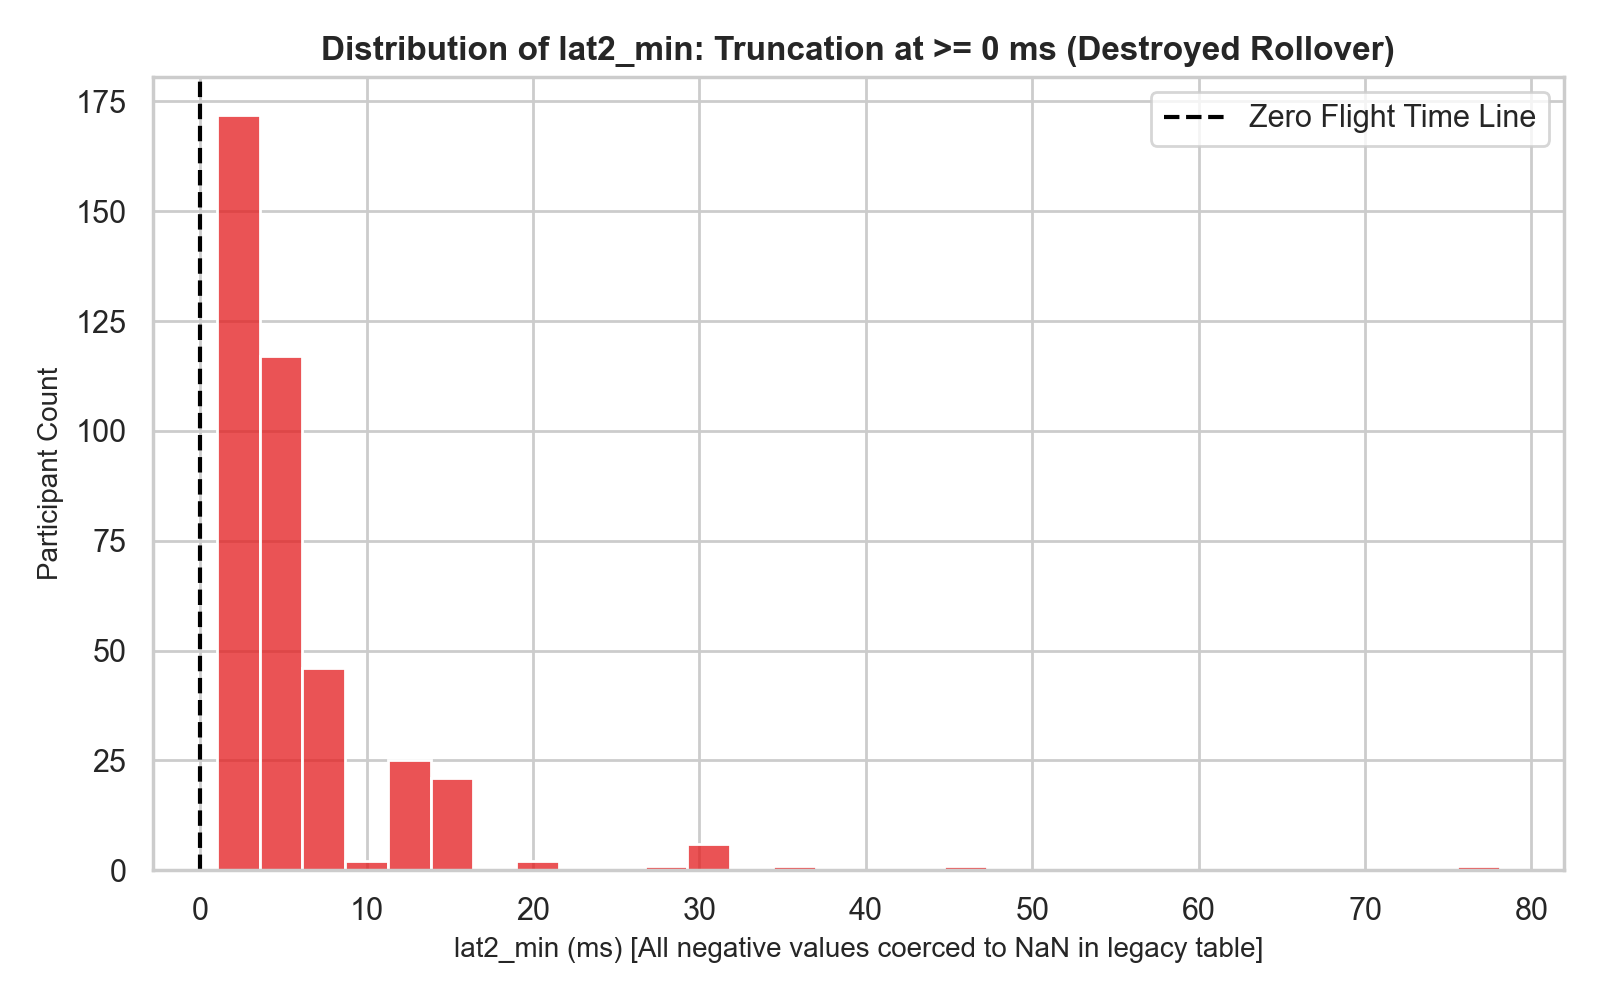


=== Figure 5: Spearman Correlation Matrix (Representative Timing Subset) ===


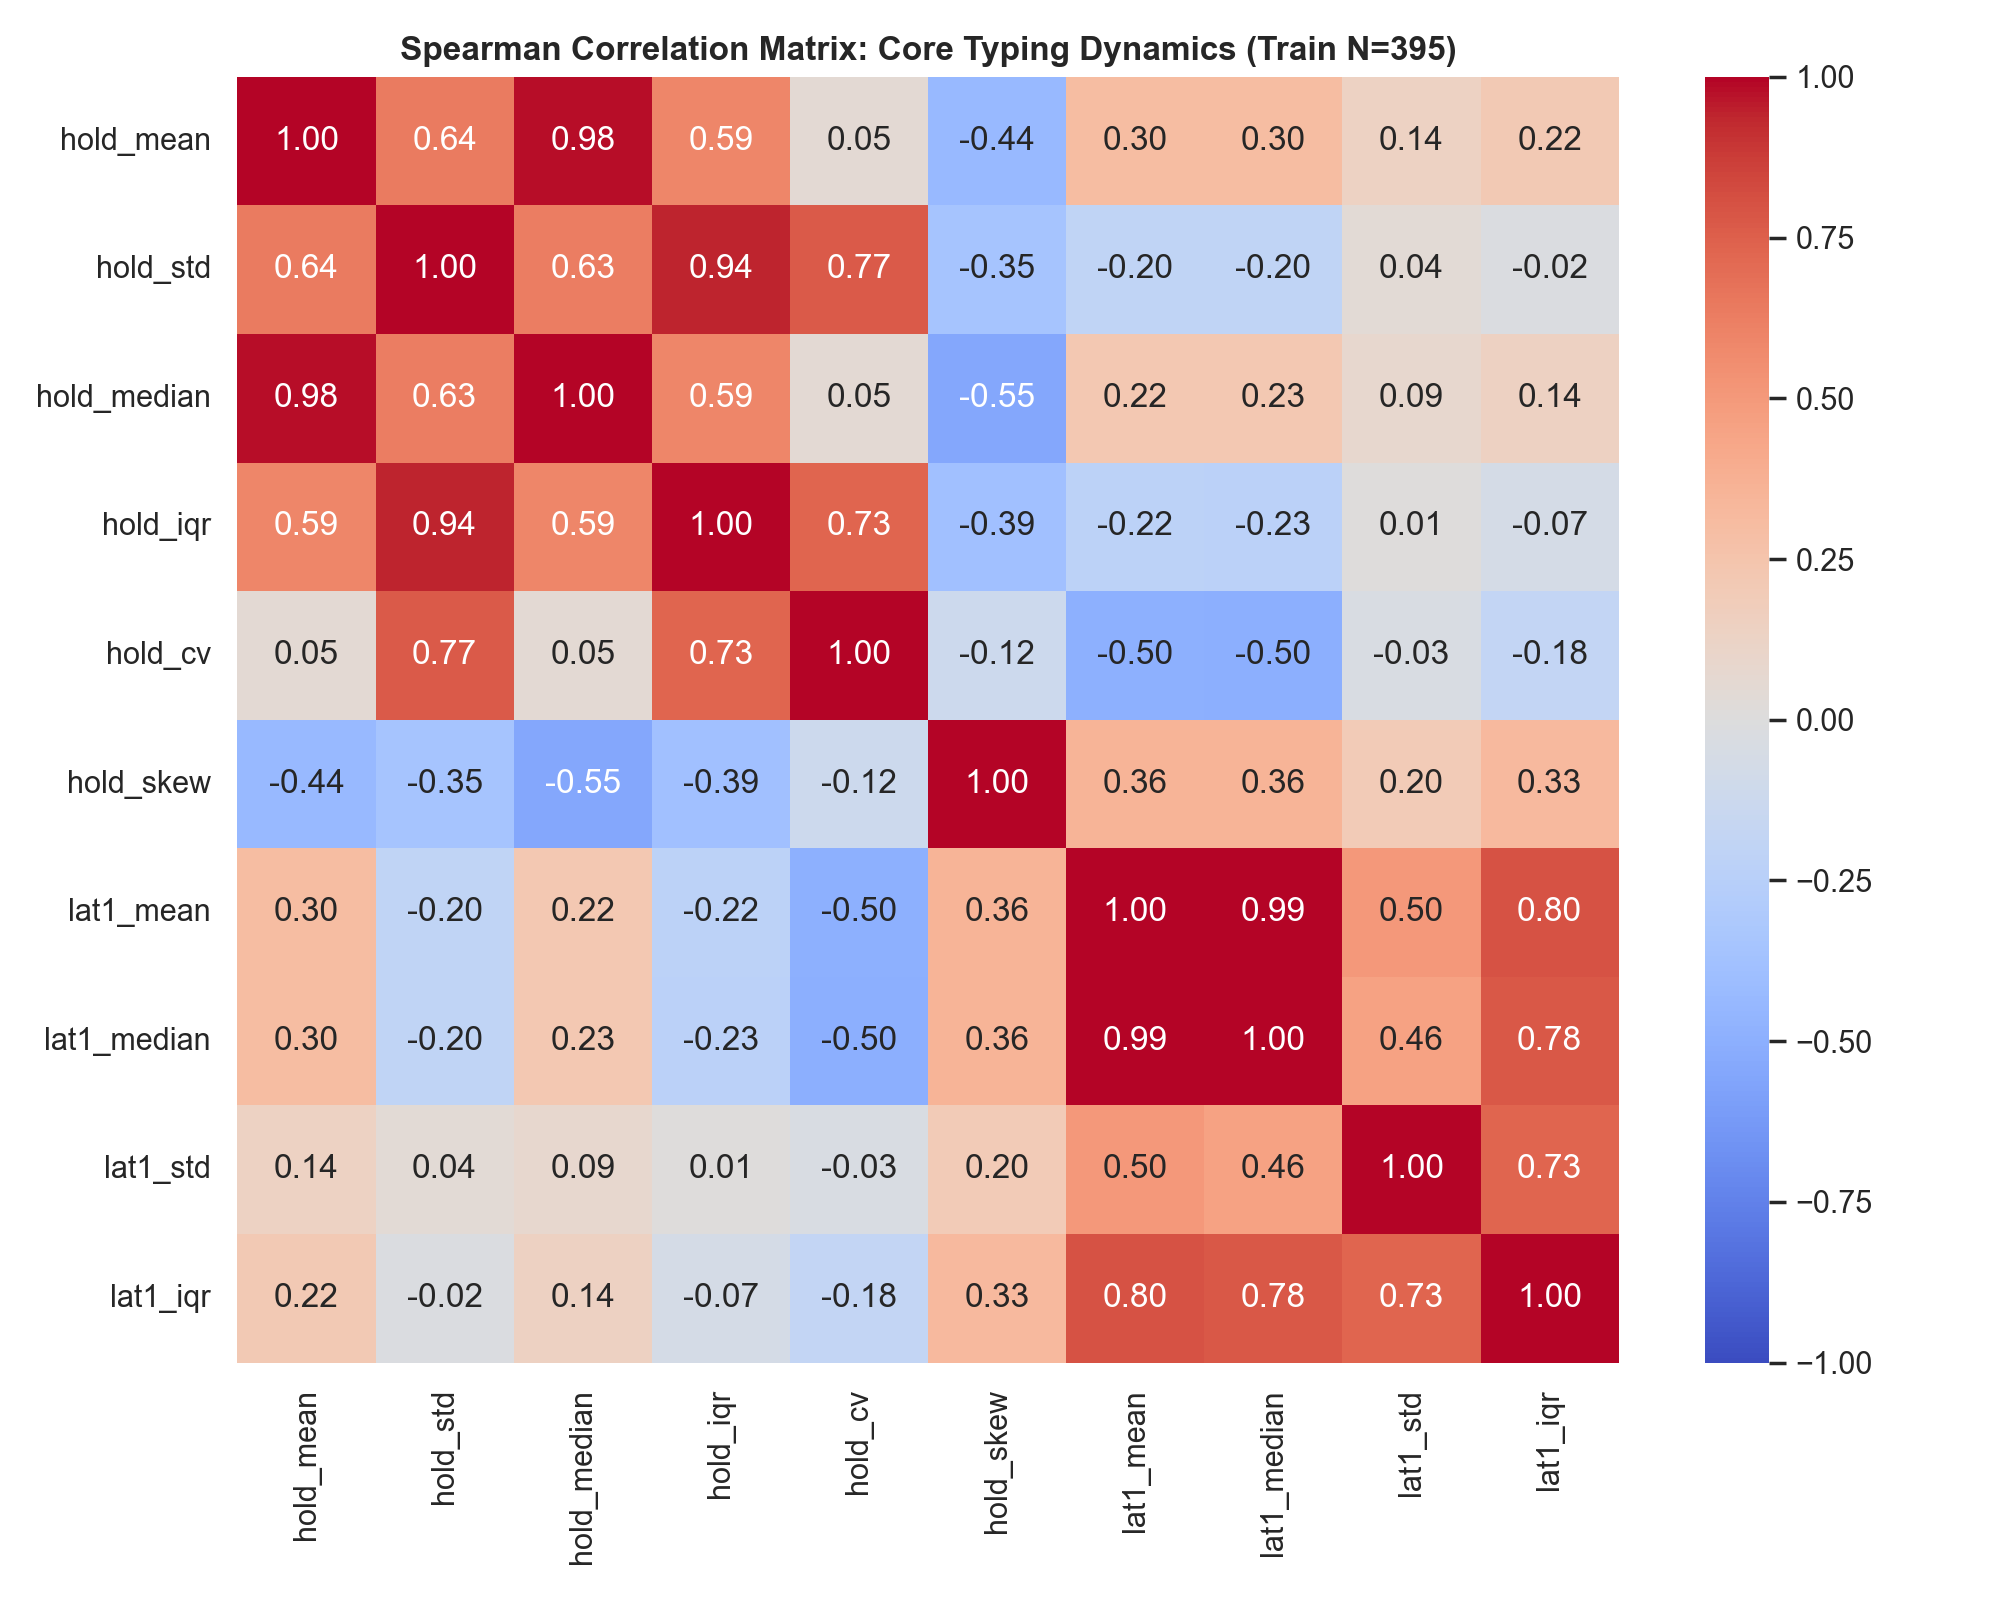


=== Figure 6: Training Cohort Label Comparisons (PD vs Control) ===


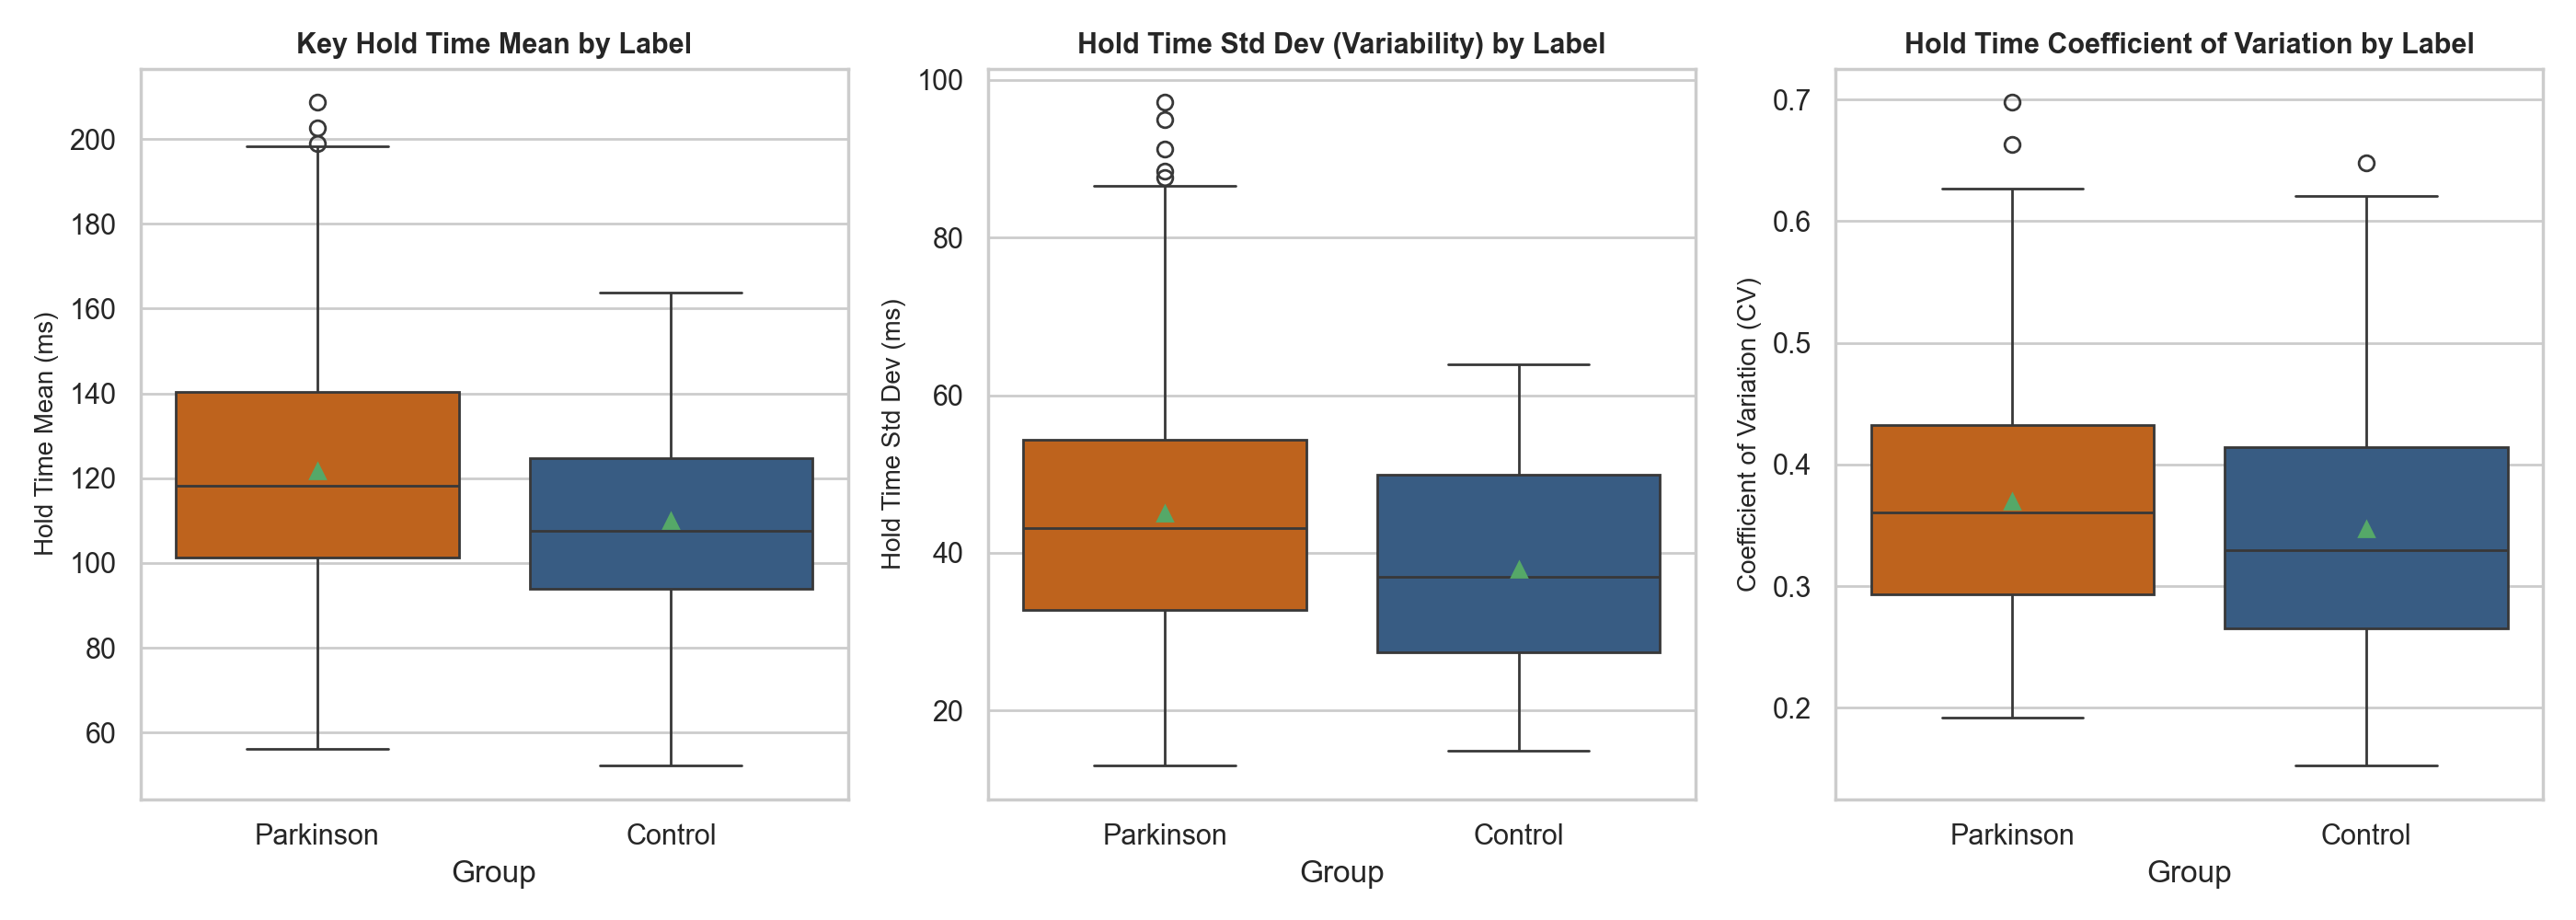

In [10]:
from IPython.display import Image, display
fig_dir = repo_root / 'reports' / 'eda' / 'figures'

figures = [
    ('Figure 1: Missingness by Transition Feature', fig_dir / 'fig1_missingness_by_feature.png'),
    ('Figure 2: Hold Time Distributions and Outlier Envelopes', fig_dir / 'fig2_hold_time_distributions.png'),
    ('Figure 3: Semantic Violation — Inadvertent Date Parsing (>100,000)', fig_dir / 'fig3_date_corruption_evidence.png'),
    ('Figure 4: Rollover Dynamics Destruction (lat2_min >= 0)', fig_dir / 'fig4_destroyed_rollover_flight_time.png'),
    ('Figure 5: Spearman Correlation Matrix (Representative Timing Subset)', fig_dir / 'fig5_correlation_heatmap.png'),
    ('Figure 6: Training Cohort Label Comparisons (PD vs Control)', fig_dir / 'fig6_label_comparison_boxplots.png')
]

for title, path in figures:
    if path.exists():
        print(f'\n=== {title} ===')
        display(Image(filename=str(path)))
    else:
        print(f'Missing figure: {path}')

## 10. Summary & Handoff to Phase 6
1. **Readiness Gate:** Phase 4 prerequisite gate failed due to candidate table corruption and participant omission ($N=495$ vs verified $N=597$).
2. **Required Preprocessing in Phase 6:**
   - Re-extract features from raw keystroke logs (`data/raw/`) for all 597 participants.
   - Purge corrupted date string columns.
   - Restore negative flight times to model rollover typing.
   - Prune redundant collinear pairs ($|\rho| \ge 0.90$).
3. **Phase Boundary:** Complete Phase 5 exploratory analysis. No model training, imputation, or data mutation has been performed.